# Screening a library

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/igbaskin/cmf-qsar/blob/main/docs/tutorials/05_screening.ipynb)

A model fitted on a series can score molecules that have not been made. Two things make
that different from predicting a test set.

The first is memory. Everything in the other notebooks loads a data set, builds every molecule's
fields and keeps them. That is right for 88 training molecules and impossible for a library of
100 000: predicting with a kernel method needs only the rows `K(X, X_train)`, one row per new
molecule, so nothing about the library has to be in memory at once and nothing about it has to be
kept after its score is written.

The second is what the score means. A library is mostly molecules unlike the training set, a
kernel method answers the training mean for those, and a point estimate cannot be told from a
real prediction. This notebook screens a small library, reads the spread beside every prediction,
and measures what the ranking is worth.

In [1]:
# Run this cell first. On Google Colab it fetches the repository and installs the package;
# on a local checkout it only moves to the repository root, so that the example paths work.
import os, subprocess, sys

if "google.colab" in sys.modules:
    if not os.path.exists("cmf-qsar"):
        subprocess.run(["git", "clone", "-q", "https://github.com/igbaskin/cmf-qsar.git"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "./cmf-qsar"], check=True)
    os.chdir("cmf-qsar")
else:
    while not os.path.exists("pyproject.toml") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")
print("working in", os.getcwd())

working in C:\Users\baski\work\claude\cmf


## A model of one series

The 88 thrombin inhibitors of the Sutherland collection, in the published training and test
split: 59 molecules to fit on, 29 held out.

In [2]:
from cmfqsar import AtomTable, CMFModel, FieldSet, build_fields, load_dataset

ds = load_dataset("examples/sutherland/THR.sdf", activity_prop="pKi")
train, test = ds.train_indices, ds.test_indices
print(len(ds), "inhibitors:", len(train), "training,", len(test), "held out")
print("pKi from %.2f to %.2f, training mean %.2f" % (ds.activity.min(), ds.activity.max(),
                                                     ds.activity[train].mean()))

fs = FieldSet.create(alpha=0.5)
mf = [build_fields(m, fs, n) for m, n in zip(ds.mols, ds.names)]
model = CMFModel(fieldset=fs, method="krr", params={"lam": 0.01})
model.fit(AtomTable.from_molecules([mf[i] for i in train]), ds.activity[train], cv_folds=10)
print("q2 = %.3f, r2 = %.3f" % (model.stats.q2, model.stats.r2))

88 inhibitors: 59 training, 29 held out
pKi from 4.36 to 8.48, training mean 6.72


q2 = 0.570, r2 = 0.967


## A library to screen

A screening result is a property of the background as much as of the model, so the background has
to be stated. Here it is the file `examples/decoys/THR_decoys.sdf`: 100 molecules taken from the
other series of the collection, presumed inactive against thrombin, and placed in the thrombin
frame by maximising their field similarity to the actives. That placement flatters the model,
because a real library has to choose a pose without knowing the actives.

The library file is the 29 held-out inhibitors and those 100 molecules together, which is the
shape of a real screening run: a few molecules worth finding in a crowd of molecules that are
not.

In [3]:
import tempfile

from rdkit import Chem

library = os.path.join(tempfile.gettempdir(), "thr_library.sdf")
names, truth = [], []
with Chem.SDWriter(library) as w:
    for i in test:                                   # the held-out inhibitors
        m = Chem.Mol(ds.mols[i])
        m.SetProp("_Name", ds.names[i])
        w.write(m)
        names.append(ds.names[i])
        truth.append(1)
    for k, m in enumerate(Chem.SDMolSupplier("examples/decoys/THR_decoys.sdf", removeHs=False)):
        if m is None:
            continue
        name = m.GetProp("_Name") if m.HasProp("_Name") else "decoy_%d" % (k + 1)
        m.SetProp("_Name", name)
        w.write(m)
        names.append(name)
        truth.append(-1)

print(len(names), "molecules in the library:", truth.count(1), "inhibitors,",
      truth.count(-1), "presumed inactive")

129 molecules in the library: 29 inhibitors, 100 presumed inactive


## Screening without holding the library

`screen` reads the file in blocks of `chunk` molecules with a forward supplier, so the file is
streamed and never indexed. For every block it builds the fields, computes the block's kernel
rows, writes the scores to the CSV and then discards the block. The peak memory is one block of
fields plus one `chunk x n_train` kernel, whatever the length of the file.

`out` is written as the run goes, so a run stopped after an hour keeps everything it had
scored.

In [4]:
from cmfqsar.screen import ScreenSpec, screen

scores_csv = os.path.join(tempfile.gettempdir(), "thr_scores.csv")
report = screen(model, library, ScreenSpec(beta=1.0, top=10, chunk=50), out=scores_csv)
print(report.describe())

129 molecules scored in 0.5 s (260 per second), 3 blocks, peak kernel block 0.0 MB
the best of them:
  decoy_COX2_9-29                  score   +8.231   prediction   +9.032   sd 0.801
  05                               score   +7.768   prediction   +7.884   sd 0.116
  decoy_COX2_1-31                  score   +7.640   prediction   +8.550   sd 0.910
  20                               score   +7.596   prediction   +7.776   sd 0.180
  11                               score   +7.596   prediction   +7.916   sd 0.320
  82                               score   +7.569   prediction   +7.676   sd 0.107
  16                               score   +7.301   prediction   +7.405   sd 0.104
  21                               score   +7.132   prediction   +7.249   sd 0.117
  01                               score   +7.076   prediction   +7.369   sd 0.293
  30                               score   +7.036   prediction   +7.286   sd 0.250


## What the score is

With `beta = 1` the score is the lower confidence bound, `prediction - 1 x sd`, which is what a
library should normally be ranked by. The standard deviation is always in the CSV, and it is the
column that tells you when the model has nothing to contribute: a molecule unlike anything in the
training set comes back at the training mean with a wide spread.

In [5]:
import numpy as np

rows = {}
with open(scores_csv) as fh:
    next(fh)                                         # name,score,prediction,sd
    for line in fh:
        name, s, p, sd = line.rstrip("\n").split(",")
        rows[name] = (float(s), float(p), float(sd))

score = np.array([rows[n][0] for n in names])
pred = np.array([rows[n][1] for n in names])
sd = np.array([rows[n][2] for n in names])
y = np.array(truth, float)

print("%-20s%-16s%-14s%s" % ("", "score", "prediction", "sd"))
for label, keep in (("the 29 inhibitors", y > 0), ("the 100 others", y < 0)):
    print("%-20s%5.2f +- %-7.2f%5.2f         %.2f"
          % (label, score[keep].mean(), score[keep].std(), pred[keep].mean(), sd[keep].mean()))
print()
print("the training mean is %.2f, the spread of the training activities %.2f"
      % (ds.activity[train].mean(), ds.activity[train].std()))

                    score           prediction    sd
the 29 inhibitors    6.34 +- 0.90    6.69         0.35
the 100 others       3.94 +- 1.63    5.34         1.40

the training mean is 6.72, the spread of the training activities 0.95


The inhibitors are predicted at 6.69 with a spread of 0.35; the others at 5.34 with a spread of
1.40, four times as wide. The second row is the model saying, correctly, that most of this library
is not its business. Subtracting one standard deviation therefore separates the two groups more
than the prediction alone does, which the next cell measures.

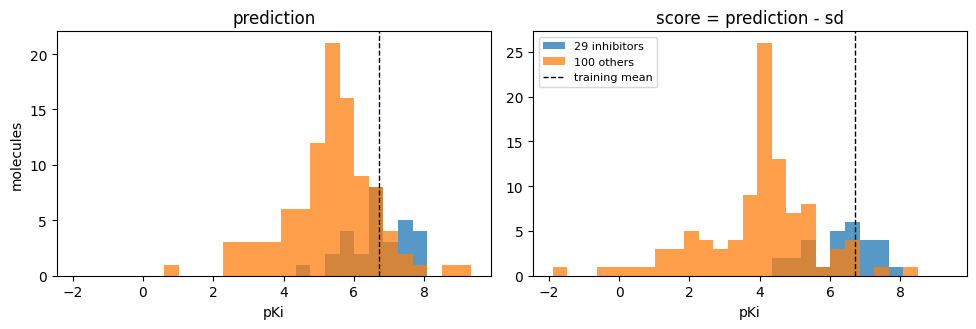

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
bins = np.linspace(min(score.min(), pred.min()) - 0.3, max(score.max(), pred.max()) + 0.3, 28)
for a, v, title in ((ax[0], pred, "prediction"), (ax[1], score, "score = prediction - sd")):
    a.hist(v[y > 0], bins=bins, alpha=0.75, label="29 inhibitors")
    a.hist(v[y < 0], bins=bins, alpha=0.75, label="100 others")
    a.axvline(ds.activity[train].mean(), color="k", lw=1, ls="--", label="training mean")
    a.set_title(title)
    a.set_xlabel("pKi")
ax[0].set_ylabel("molecules")
ax[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## What the ranking is worth

`screening_scores` gives the area under the curve and the enrichment at the top of the list. The
enrichment factor at a fraction *f* is the share of actives in the top *f* of the ranking divided
by *f*, so 1.0 is random and `max_ef` is the most that the active rate allows.

In [7]:
from cmfqsar.model import screening_scores

bound = screening_scores(y, score)                   # ranked by prediction - sd
plain = screening_scores(y, pred)                    # ranked by the prediction alone
print("%-20s%-13s%-18s%s" % ("", "prediction", "prediction - sd", "the most possible"))
for key, label in (("auc", "AUC"), ("ef_10", "enrichment at 10 %"),
                   ("bedroc_20", "BEDROC (alpha 20)")):
    best = "%.2f" % bound["max_ef"] if key == "ef_10" else "1.00"
    print("%-20s%-13.3f%-18.3f%s" % (label, plain[key], bound[key], best))
print()
print("%d molecules, %d of them inhibitors (%.0f %%)"
      % (bound["n"], bound["n_actives"], 100 * bound["active_rate"]))

                    prediction   prediction - sd   the most possible
AUC                 0.830        0.915             1.00
enrichment at 10 %  2.737        3.422             4.45
BEDROC (alpha 20)   0.547        0.685             1.00

129 molecules, 29 of them inhibitors (22 %)


The lower confidence bound is better on every one of the three: AUC 0.92 against 0.83,
enrichment at 10 % of the list 3.42 against 2.74 out of a possible 4.45. That is the reason the
standard deviation is computed for every block even when `beta` is zero.

Three things to keep in mind about numbers like these.

**This library is small.** 129 molecules make the top fractions coarse: 1 % of the list is one
molecule, so `ef_1` here is either 0 or 4.45 and says nothing. Only the AUC and the enrichment at
5 or 10 % mean anything on a library of this size.

**The top of the list is not clean.** Two molecules from the COX-2 series are predicted above
every held-out inhibitor (9.03 and 8.55 against a highest active of 7.88), and the confidence
bound does not remove them, because the model is confident about them. A field model scores what
the field resembles; whether the molecule binds thrombin is a question it was never asked.

**The background decides the number.** These 100 molecules were posed by maximising their field
similarity to the actives, which is the best case. On a published benchmark, with inactives that
were actually measured and poses chosen without knowing the actives, the same approach does much
worse: the measurement is in the manual, section *Screening done on a public benchmark*, and it is
the least favourable measurement in the repository.

## From the command line

The same run, without Python:

```bash
python cmf_cli.py screen model.cmf library.sdf --out scores.csv --beta 1.0 --top 25
```

`--chunk` sets the block size, `--pose` places each molecule by maximising its field similarity to
the training molecules (about half a second per molecule, far more than the scoring), and
`--pose-conformers N` generates N conformations of each and poses every one.

Where to read further: *Screening a library that does not fit in memory* for the streaming and its
measured memory, *How certain is one prediction? Conformal intervals* for an interval with a
coverage guarantee instead of a standard deviation, and *One-class classification and virtual
screening* for the case where there are no measured activities to fit on at all.